<a href="https://colab.research.google.com/github/enoch1472/Titanic-Survival-Prediction/blob/main/Titanic_Survival_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn

In [3]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv("train.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


<Axes: >

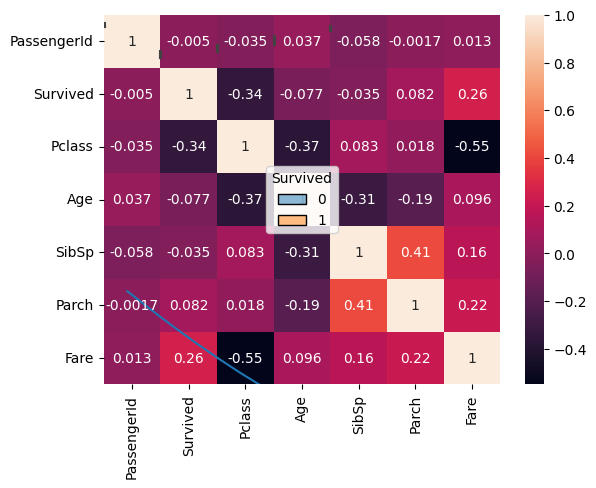

In [6]:
df.info()


df.describe()



df.isnull().sum()


df["Survived"].value_counts(normalize=True)

sns.barplot(x="Sex", y="Survived", data=df)
sns.barplot(x="Pclass", y="Survived", data=df)
sns.histplot(data=df, x="Age", hue="Survived", kde=True)
sns.heatmap(df.corr(numeric_only=True), annot=True)

In [9]:
# the Age has quite a few missing values, so I fill them with the median.
# I use the median instead of the mean because a few very old
# passengers would pull the mean up.
df["Age"] = df["Age"].fillna(df["Age"].median())

# Embarked only has 2 missing, so I just use the most common port
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Cabin is about 77% empty, so filling it in would be mostly guessing.
# Instead I keep a simple 1/0 flag for whether a cabin was recorded.
# The "if" check means I can re-run this cell without it crashing.
if "Cabin" in df.columns:
    df["HasCabin"] = df["Cabin"].notnull().astype(int)
    df = df.drop("Cabin", axis=1)

print(df.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
HasCabin       0
dtype: int64


In [10]:
# Titles like Mr, Mrs, Miss are hidden inside the Name column.
# They can say something about age and status, so I pull them out.
df["Title"] = df["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)

# the rare ones together so I don't end up with loads of tiny categories


df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
common_titles = ["Mr", "Mrs", "Miss", "Master"]


df["Title"] = df["Title"].apply(lambda t: t if t in common_titles else "Rare")

# SibSp and Parch are both about family, so I combine them
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

# Travelling alone might matter, so I add a flag for it
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

print(df["Title"].value_counts())

Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64


In [11]:
# These columns i noted don't help the model:
# PassengerId is just a row number, Name is unique per person and I
# andIalready got the Title out of it), Ticket is mostly random codes
df = df.drop(["PassengerId", "Name", "Ticket"], axis=1)

df = pd.get_dummies(df, columns=["Sex", "Embarked", "Title"], drop_first=True)

df.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,HasCabin,FamilySize,IsAlone,Sex_male,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,0,3,22.0,1,0,7.2500,0,2,0,True,False,True,False,True,False,False
1,1,1,38.0,1,0,71.2833,1,2,0,False,False,False,False,False,True,False
2,1,3,26.0,0,0,7.9250,0,1,1,False,False,True,True,False,False,False
3,1,1,35.0,1,0,53.1000,1,2,0,False,False,True,False,False,True,False
4,0,3,35.0,0,0,8.0500,0,1,1,True,False,True,False,True,False,False


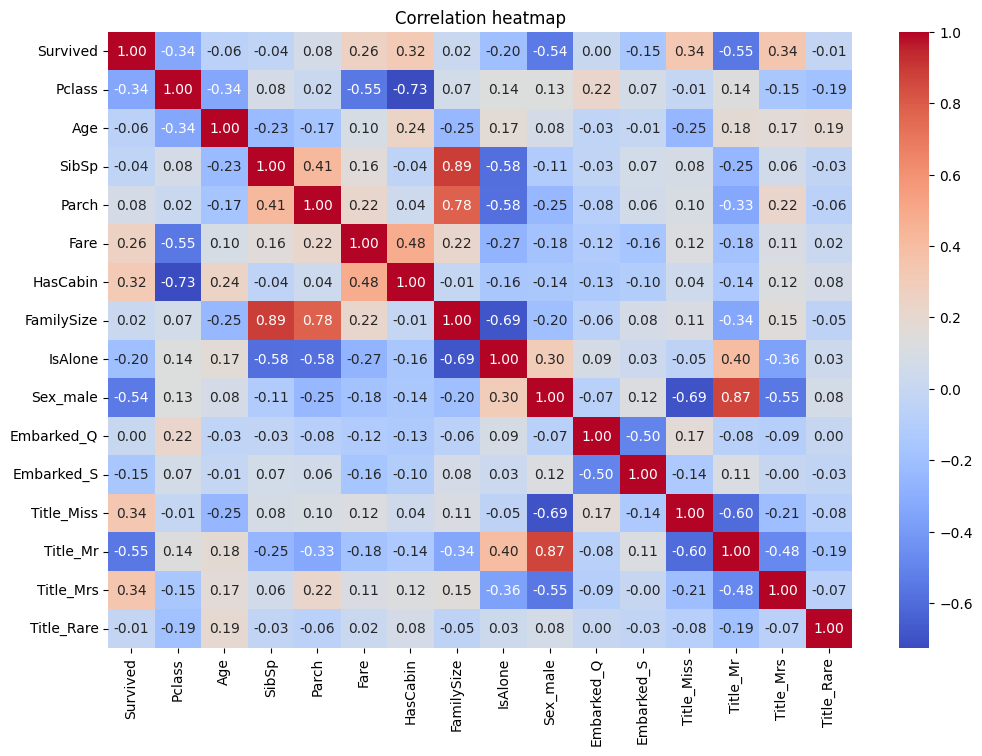

Survived      1.000000
Title_Mrs     0.341994
Title_Miss    0.335636
HasCabin      0.316912
Fare          0.257307
Parch         0.081629
FamilySize    0.016639
Embarked_Q    0.003650
Title_Rare   -0.012054
SibSp        -0.035322
Age          -0.064910
Embarked_S   -0.149683
IsAlone      -0.203367
Pclass       -0.338481
Sex_male     -0.543351
Title_Mr     -0.549199
Name: Survived, dtype: float64


In [12]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.show()

# Correlation with Survived specifically, sorted
print(df.corr()["Survived"].sort_values(ascending=False))

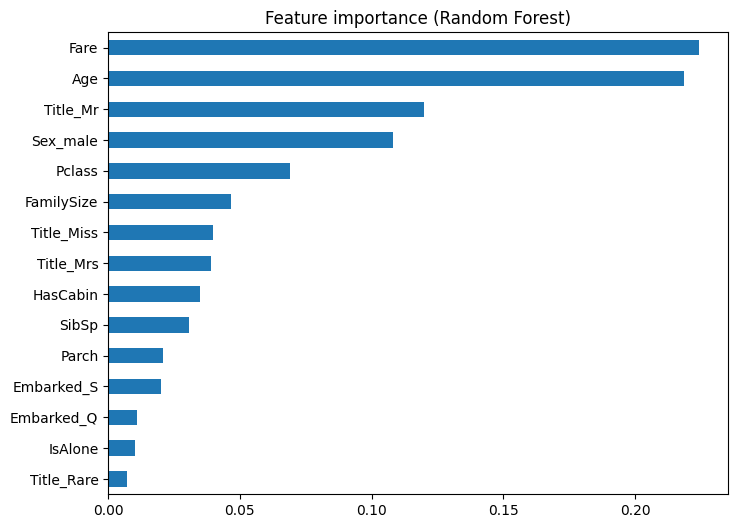

In [13]:
from sklearn.ensemble import RandomForestClassifier

X_all = df.drop("Survived", axis=1)
y_all = df["Survived"]

rf_check = RandomForestClassifier(n_estimators=200, random_state=42)
rf_check.fit(X_all, y_all)

importances = pd.Series(rf_check.feature_importances_, index=X_all.columns)
importances.sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Feature importance (Random Forest)")
plt.show()

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop("Survived", axis=1)
y = df["Survived"]

# 80% to train on, 20% held back to test.

# and random_state makes my results repeatable.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# (Fare is in the hundreds, but most columns are 0/1).

# I fit the scaler on the training data only so nothing leaks from the test set.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

===== Logistic Regression =====
              precision    recall  f1-score   support

           0       0.86      0.88      0.87       110
           1       0.80      0.77      0.79        69

    accuracy                           0.84       179
   macro avg       0.83      0.82      0.83       179
weighted avg       0.84      0.84      0.84       179



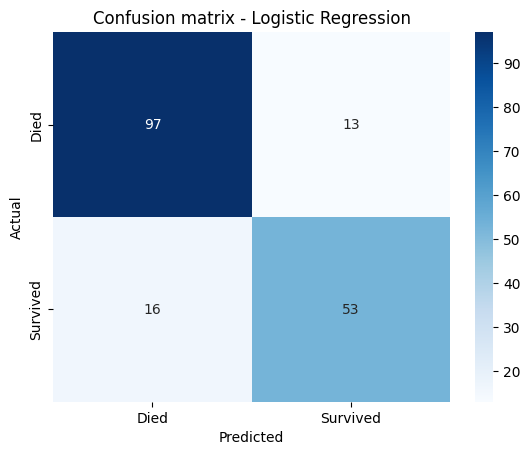

===== Decision Tree =====
              precision    recall  f1-score   support

           0       0.84      0.86      0.85       110
           1       0.77      0.74      0.76        69

    accuracy                           0.82       179
   macro avg       0.81      0.80      0.80       179
weighted avg       0.81      0.82      0.81       179



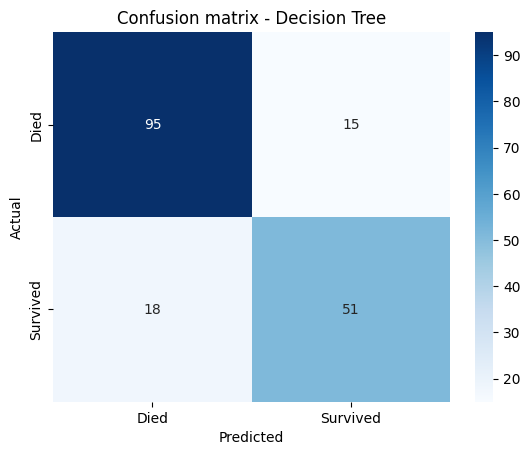

===== Random Forest =====
              precision    recall  f1-score   support

           0       0.84      0.84      0.84       110
           1       0.74      0.75      0.75        69

    accuracy                           0.80       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.81      0.80      0.80       179



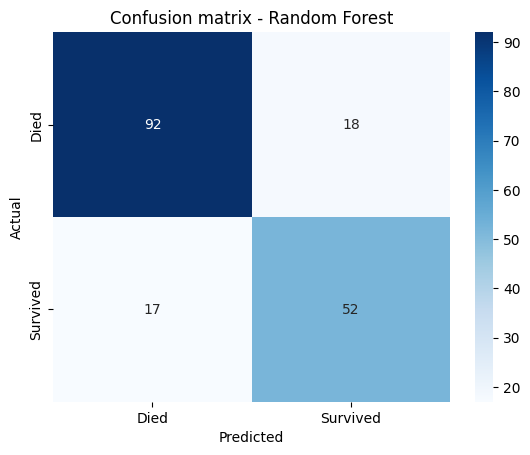

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.838,0.803,0.768,0.785
1,Decision Tree,0.816,0.773,0.739,0.756
2,Random Forest,0.804,0.743,0.754,0.748


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

# A helper so I don't repeat the same evaluation code for every model
def evaluate_model(name, model, X_tr, X_te):
    model.fit(X_tr, y_train)
    preds = model.predict(X_te)

    print(f"===== {name} =====")
    print(classification_report(y_test, preds))

    # Confusion matrix
    sns.heatmap(confusion_matrix(y_test, preds), annot=True, fmt="d", cmap="Blues",
                xticklabels=["Died", "Survived"], yticklabels=["Died", "Survived"])
    plt.title(f"Confusion matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "F1": f1_score(y_test, preds),
    }

results = []

# Logistic Regression (a simple, interpretable baseline)
results.append(evaluate_model("Logistic Regression",
                              LogisticRegression(max_iter=1000),
                              X_train_scaled, X_test_scaled))

# My Decision Tree (max_depth stops it from just memorising the data)
results.append(evaluate_model("Decision Tree",
                              DecisionTreeClassifier(max_depth=4, random_state=42),
                              X_train, X_test))

# Random Forest (lots of trees voting, usually more robust)
results.append(evaluate_model("Random Forest",
                              RandomForestClassifier(n_estimators=200, random_state=42),
                              X_train, X_test))

pd.DataFrame(results).round(3)

In [17]:
from sklearn.model_selection import cross_val_score

# One 80/20 split can be lucky or unlucky, so I also check with 5-fold
# i just feel like cross-validation, which tests the model on 5 different slices of the data
models_to_cv = {
    "Logistic Regression": (LogisticRegression(max_iter=1000), scaler.transform(X)),
    "Decision Tree": (DecisionTreeClassifier(max_depth=4, random_state=42), X),
    "Random Forest": (RandomForestClassifier(n_estimators=200, random_state=42), X),
}

for name, (model, features) in models_to_cv.items():
    scores = cross_val_score(model, features, y, cv=5, scoring="accuracy")
    print(f"{name}: mean accuracy = {scores.mean():.3f} (+/- {scores.std():.3f})")

Logistic Regression: mean accuracy = 0.827 (+/- 0.026)
Decision Tree: mean accuracy = 0.825 (+/- 0.021)
Random Forest: mean accuracy = 0.802 (+/- 0.037)


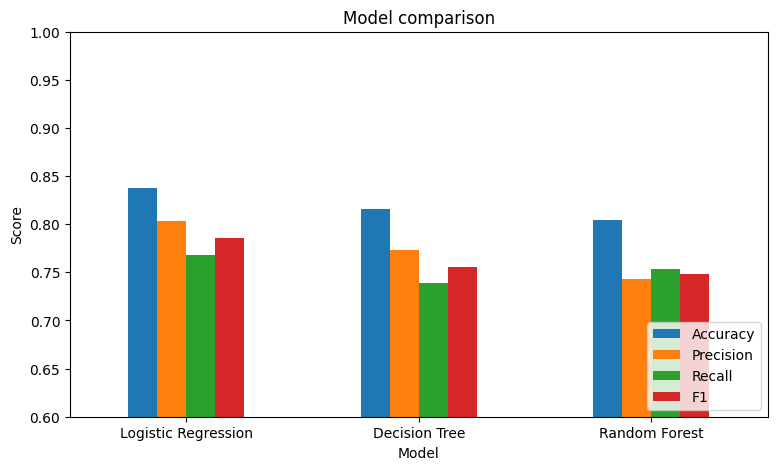

In [18]:
# My Final comparison chart of every model's scores
comparison = pd.DataFrame(results).set_index("Model")
comparison.plot(kind="bar", figsize=(9, 5))
plt.title("Model comparison")
plt.ylabel("Score")
plt.ylim(0.6, 1.0)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()